
 DATA CLUSTERING USING PSO
1. Generate Dataset
2. Display Dataset
3. Run PSO Clustering
4. Display PSO Clustering Result
5. Compare PSO with K-Means
6. Display Convergence Graph
7. Exit

Enter your choice (1-7): 1

Dataset generated successfully!
Total data points: 400
Number of clusters: 4

First five data points:
[[-9.86267124  8.72735826]
 [-4.60499371  9.67180813]
 [-9.03492221  7.10534406]
 [ 5.41997462  1.85552378]
 [ 5.09659124  2.8816222 ]]

 DATA CLUSTERING USING PSO
1. Generate Dataset
2. Display Dataset
3. Run PSO Clustering
4. Display PSO Clustering Result
5. Compare PSO with K-Means
6. Display Convergence Graph
7. Exit

Enter your choice (1-7): 2


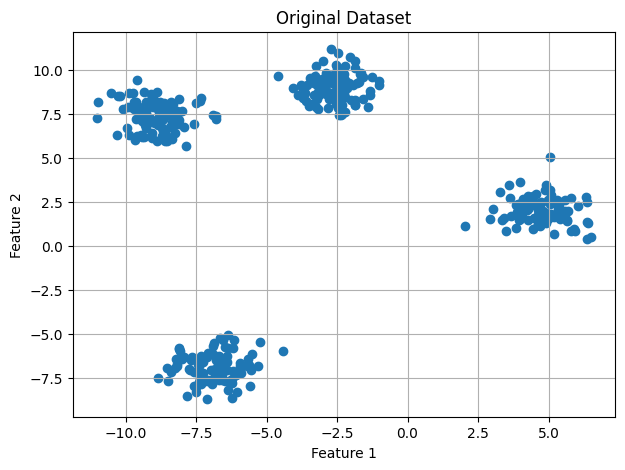


 DATA CLUSTERING USING PSO
1. Generate Dataset
2. Display Dataset
3. Run PSO Clustering
4. Display PSO Clustering Result
5. Compare PSO with K-Means
6. Display Convergence Graph
7. Exit

Enter your choice (1-7): 3

========== RUNNING PSO ==========
Iteration 1/80 | Best SSE: 2582.67
Iteration 2/80 | Best SSE: 2582.67
Iteration 3/80 | Best SSE: 2409.25
Iteration 4/80 | Best SSE: 2235.30
Iteration 5/80 | Best SSE: 2038.32
Iteration 6/80 | Best SSE: 1309.20
Iteration 7/80 | Best SSE: 1309.20
Iteration 8/80 | Best SSE: 1264.50
Iteration 9/80 | Best SSE: 1147.87
Iteration 10/80 | Best SSE: 1147.87
Iteration 11/80 | Best SSE: 1130.76
Iteration 12/80 | Best SSE: 1119.95
Iteration 13/80 | Best SSE: 845.83
Iteration 14/80 | Best SSE: 822.25
Iteration 15/80 | Best SSE: 792.77
Iteration 16/80 | Best SSE: 792.77
Iteration 17/80 | Best SSE: 773.94
Iteration 18/80 | Best SSE: 620.20
Iteration 19/80 | Best SSE: 608.32
Iteration 20/80 | Best SSE: 608.32
Iteration 21/80 | Best SSE: 608.32
Iteration 22

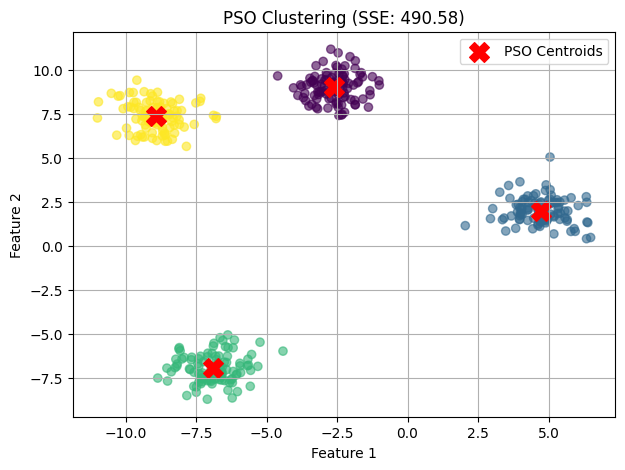


 DATA CLUSTERING USING PSO
1. Generate Dataset
2. Display Dataset
3. Run PSO Clustering
4. Display PSO Clustering Result
5. Compare PSO with K-Means
6. Display Convergence Graph
7. Exit

Enter your choice (1-7): 5

========== CLUSTERING COMPARISON ==========
PSO SSE: 490.58
K-Means SSE: 490.57


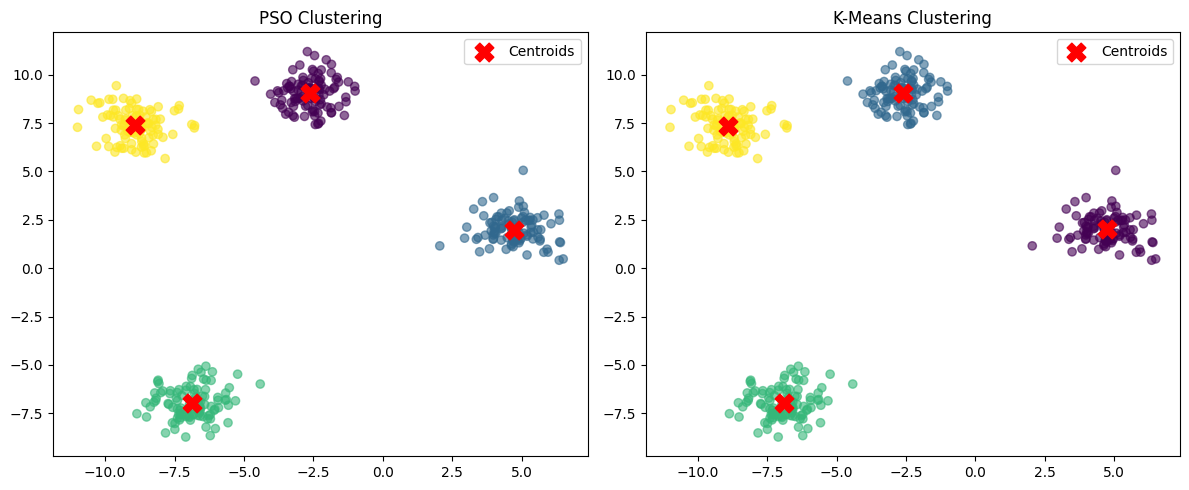


 DATA CLUSTERING USING PSO
1. Generate Dataset
2. Display Dataset
3. Run PSO Clustering
4. Display PSO Clustering Result
5. Compare PSO with K-Means
6. Display Convergence Graph
7. Exit

Enter your choice (1-7): 6


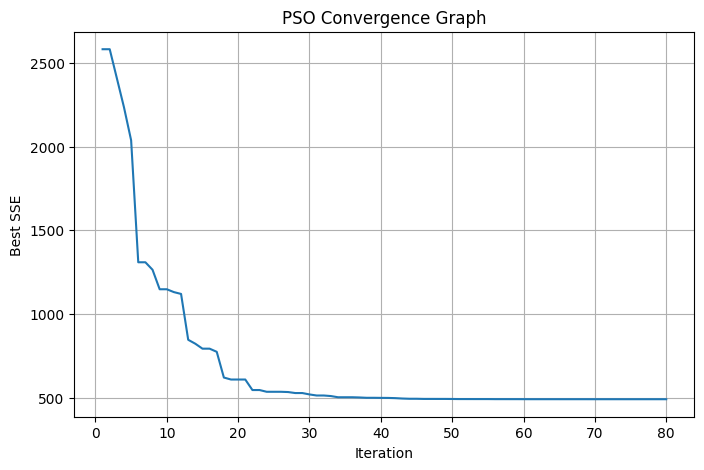


 DATA CLUSTERING USING PSO
1. Generate Dataset
2. Display Dataset
3. Run PSO Clustering
4. Display PSO Clustering Result
5. Compare PSO with K-Means
6. Display Convergence Graph
7. Exit

Enter your choice (1-7): 7

Exiting Program. Thank You!


In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans


# ==========================================
# GLOBAL VARIABLES
# ==========================================

X = None

pso_centroids = None
pso_labels = None
pso_sse = None

kmeans = None
kmeans_labels = None

history = []

N_CLUSTERS = 4
N_PARTICLES = 30
MAX_ITERATIONS = 80

w = 0.6
c1 = 1.8
c2 = 1.8


# ==========================================
# 1. GENERATE DATASET
# ==========================================

def generate_dataset():

    global X
    global pso_centroids, pso_labels, pso_sse
    global kmeans, kmeans_labels, history

    # Generate sample data
    X, y = make_blobs(
        n_samples=400,
        centers=N_CLUSTERS,
        cluster_std=0.8,
        random_state=42
    )

    # Reset previous results
    pso_centroids = None
    pso_labels = None
    pso_sse = None
    kmeans = None
    kmeans_labels = None
    history = []

    print("\nDataset generated successfully!")
    print("Total data points:", len(X))
    print("Number of clusters:", N_CLUSTERS)

    print("\nFirst five data points:")
    print(X[:5])


# ==========================================
# 2. DISPLAY DATASET
# ==========================================

def display_dataset():

    if X is None:
        print("\nGenerate dataset first!")
        return

    plt.figure(figsize=(7, 5))

    plt.scatter(X[:, 0], X[:, 1])

    plt.title("Original Dataset")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

    plt.grid()
    plt.show()


# ==========================================
# 3. FITNESS FUNCTION
# ==========================================

def calculate_fitness(data, centroids):

    # Calculate distance of each point from each centroid
    distances = np.linalg.norm(
        data[:, np.newaxis, :] - centroids[np.newaxis, :, :],
        axis=2
    )

    # Find minimum distance for every data point
    min_distances = np.min(distances, axis=1)

    # Calculate Sum of Squared Errors
    sse = np.sum(min_distances ** 2)

    return sse


# ==========================================
# 4. ASSIGN DATA POINTS TO CLUSTERS
# ==========================================

def assign_clusters(data, centroids):

    distances = np.linalg.norm(
        data[:, np.newaxis, :] - centroids[np.newaxis, :, :],
        axis=2
    )

    labels = np.argmin(distances, axis=1)

    return labels


# ==========================================
# 5. RUN PARTICLE SWARM OPTIMIZATION
# ==========================================

def run_pso():

    global pso_centroids, pso_labels, pso_sse, history

    if X is None:
        print("\nGenerate dataset first!")
        return

    np.random.seed(42)

    n_samples, dimensions = X.shape

    data_min = np.min(X, axis=0)
    data_max = np.max(X, axis=0)

    # Initialize particle positions
    positions = np.random.uniform(
        data_min,
        data_max,
        size=(N_PARTICLES, N_CLUSTERS, dimensions)
    )

    # Initialize velocities
    velocities = np.zeros_like(positions)

    # Initialize personal best positions
    pbest_positions = positions.copy()

    pbest_scores = np.full(N_PARTICLES, float('inf'))

    # Initialize global best
    gbest_position = None
    gbest_score = float('inf')

    history = []

    print("\n========== RUNNING PSO ==========")

    for iteration in range(MAX_ITERATIONS):

        # Evaluate fitness of every particle
        for i in range(N_PARTICLES):

            score = calculate_fitness(
                X,
                positions[i]
            )

            # Update personal best
            if score < pbest_scores[i]:

                pbest_scores[i] = score
                pbest_positions[i] = positions[i].copy()

            # Update global best
            if score < gbest_score:

                gbest_score = score
                gbest_position = positions[i].copy()

        # Update velocity and position
        for i in range(N_PARTICLES):

            r1 = np.random.rand(N_CLUSTERS, dimensions)
            r2 = np.random.rand(N_CLUSTERS, dimensions)

            # Cognitive component
            cognitive = c1 * r1 * (
                pbest_positions[i] - positions[i]
            )

            # Social component
            social = c2 * r2 * (
                gbest_position - positions[i]
            )

            # Velocity update
            velocities[i] = (
                w * velocities[i]
                + cognitive
                + social
            )

            # Position update
            positions[i] += velocities[i]

            # Keep centroids within data boundaries
            positions[i] = np.clip(
                positions[i],
                data_min,
                data_max
            )

        history.append(gbest_score)

        print(
            f"Iteration {iteration + 1}/{MAX_ITERATIONS} "
            f"| Best SSE: {gbest_score:.2f}"
        )

    # Store final results
    pso_centroids = gbest_position
    pso_sse = gbest_score

    pso_labels = assign_clusters(
        X,
        pso_centroids
    )

    print("\nPSO Clustering Completed!")
    print("Final PSO SSE:", round(pso_sse, 2))


# ==========================================
# 6. DISPLAY PSO CLUSTERING GRAPH
# ==========================================

def display_pso_result():

    if pso_centroids is None:
        print("\nRun PSO first!")
        return

    plt.figure(figsize=(7, 5))

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=pso_labels,
        cmap='viridis',
        alpha=0.6
    )

    plt.scatter(
        pso_centroids[:, 0],
        pso_centroids[:, 1],
        color='red',
        marker='X',
        s=200,
        label='PSO Centroids'
    )

    plt.title(f"PSO Clustering (SSE: {pso_sse:.2f})")

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

    plt.legend()
    plt.grid()
    plt.show()


# ==========================================
# 7. COMPARE WITH K-MEANS
# ==========================================

def compare_kmeans():

    global kmeans, kmeans_labels

    if X is None:
        print("\nGenerate dataset first!")
        return

    if pso_centroids is None:
        print("\nRun PSO first!")
        return

    # Apply K-Means
    kmeans = KMeans(
        n_clusters=N_CLUSTERS,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    kmeans_labels = kmeans.labels_

    print("\n========== CLUSTERING COMPARISON ==========")

    print("PSO SSE:", round(pso_sse, 2))

    print("K-Means SSE:", round(kmeans.inertia_, 2))

    # Display both results
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # PSO graph
    axes[0].scatter(
        X[:, 0],
        X[:, 1],
        c=pso_labels,
        cmap='viridis',
        alpha=0.6
    )

    axes[0].scatter(
        pso_centroids[:, 0],
        pso_centroids[:, 1],
        color='red',
        marker='X',
        s=180,
        label='Centroids'
    )

    axes[0].set_title("PSO Clustering")
    axes[0].legend()

    # K-Means graph
    axes[1].scatter(
        X[:, 0],
        X[:, 1],
        c=kmeans_labels,
        cmap='viridis',
        alpha=0.6
    )

    axes[1].scatter(
        kmeans.cluster_centers_[:, 0],
        kmeans.cluster_centers_[:, 1],
        color='red',
        marker='X',
        s=180,
        label='Centroids'
    )

    axes[1].set_title("K-Means Clustering")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


# ==========================================
# 8. DISPLAY CONVERGENCE GRAPH
# ==========================================

def display_convergence():

    if not history:
        print("\nRun PSO first!")
        return

    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(history) + 1),
        history
    )

    plt.title("PSO Convergence Graph")
    plt.xlabel("Iteration")
    plt.ylabel("Best SSE")

    plt.grid()
    plt.show()


# ==========================================
# 9. MAIN MENU
# ==========================================

while True:

    print("\n======================================")
    print(" DATA CLUSTERING USING PSO")
    print("======================================")

    print("1. Generate Dataset")
    print("2. Display Dataset")
    print("3. Run PSO Clustering")
    print("4. Display PSO Clustering Result")
    print("5. Compare PSO with K-Means")
    print("6. Display Convergence Graph")
    print("7. Exit")

    choice = input("\nEnter your choice (1-7): ")

    if choice == "1":
        generate_dataset()

    elif choice == "2":
        display_dataset()

    elif choice == "3":
        run_pso()

    elif choice == "4":
        display_pso_result()

    elif choice == "5":
        compare_kmeans()

    elif choice == "6":
        display_convergence()

    elif choice == "7":
        print("\nExiting Program. Thank You!")
        break

    else:
        print("\nInvalid choice! Enter a number from 1 to 7.")
